# Customer Sentiment from Amazon Phone Reviews

This notebook builds a sentiment classifier for Amazon reviews of unlocked mobile phones. It also turns the reviews into a short list of concerns a seller can act on.

**Goal.** Predict whether a review is positive or negative from its text alone. Then explain what drives negative reviews.

**Dataset.** [Amazon Reviews Unlocked Mobile Phones](https://www.kaggle.com/datasets/PromptCloudHQ/amazon-reviews-unlocked-mobile-phones) from PromptCloud on Kaggle. It has 413,840 reviews. The columns are Product Name and Brand Name and Price and Rating and Reviews and Review Votes.

**Label rules**

| Rating | Label | Used in the classifier |
|---|---|---|
| 4 or 5 stars | positive (1) | yes |
| 1 or 2 stars | negative (0) | yes |
| 3 stars | neutral | no. Excluded from the core task |

**Workflow**

1. Draw a reproducible sample of 50,000 reviews.
2. Explore ratings and missing text and duplicates and length and vocabulary.
3. Read reviews by hand to see where star ratings and text disagree.
4. Split by product name so the test set only holds products the model never saw.
5. Compare a baseline with two feature sets for one classifier.
6. Tune a small grid with group aware cross validation on development data.
7. Freeze the pipeline and evaluate it once on the test set.
8. Summarise customer concerns for a seller.
9. Save the model and demonstrate a prediction function.

Every random step uses `random_state=42` so the notebook gives the same numbers on every run.

In [1]:
import re
import time
import warnings
from collections import Counter
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
)
from sklearn.model_selection import GridSearchCV, GroupShuffleSplit, StratifiedGroupKFold, cross_validate
from sklearn.pipeline import Pipeline

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 200)

RANDOM_STATE = 42
SAMPLE_SIZE = 50_000
DATA_PATH = Path("data/Amazon_Unlocked_Mobile.csv")
FIG_DIR = Path("reports/figures")
MODEL_DIR = Path("models")
FIG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Colors: blue for positive and orange for negative in every plot.
POS_COLOR, NEG_COLOR, GREY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "font.size": 10,
})
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

pandas 3.0.5 | scikit-learn 1.9.1


## 1. Load the data and draw a reproducible sample

The full file has about 414,000 rows. Experiments on all of it would be slow and would add little for a linear text model. We draw a simple random sample of **50,000 reviews** with a fixed seed. The sample keeps the natural rating mix of the full data.

In [2]:
raw = pd.read_csv(DATA_PATH)
print("Full dataset shape:", raw.shape)

sample = raw.sample(n=SAMPLE_SIZE, random_state=RANDOM_STATE).reset_index(drop=True)
print("Sample shape:", sample.shape)
sample.head()

Full dataset shape: (413840, 6)
Sample shape: (50000, 6)


,Product Name,Brand Name,Price,Rating,Reviews,Review Votes
0,Apple iPhone 6 Plus 128GB Factory Unlocked GSM 4G LTE Cell Phone - Gold,NaN,699.95,1,Defective phone. Works only for two days. Phone is flickering and the screen doesn't responding. Couldn't even open the slide to unlock key. I wish I could ...,5.0
1,HTC Desire 816 Dual Sim Unlocked Smartphone (White) LTE 900 / 1800 / 2100 / 2600 - International Version No Warranty,HTC,221.00,3,Cool,0.0
2,"BLU Studio 5.0 C HD Unlocked Cellphone, Black",BLU,173.44,5,Beautiful and excellent quality,1.0
3,Apple iPhone 5c 16GB (Pink) - AT&T,Apple,519.00,2,Gave 3 stars because it did not come with a charger or box. The battery was already half way gone. When I first turned it on I thought it was broke the scre...,0.0
4,BLU PURE XL Smartphone - 4G LTE GSM Unlocked - 64GB +3GB RAM - Grey,BLU,129.99,1,"High resolution camera so you can zoom in after the picture was taken, print it out and it still looks perfect. It has features of many premium phones for l...",1.0


## 2. Explore and prepare the data

### 2.1 Missing and empty reviews

In [3]:
missing = sample.isna().sum().rename("missing").to_frame()
missing["share_%"] = (missing["missing"] / len(sample) * 100).round(2)
display(missing)

review_text = sample["Reviews"].fillna("")
is_empty = review_text.str.strip().eq("")
print("Missing review text:", sample["Reviews"].isna().sum())
print("Empty or whitespace only review text:", int(is_empty.sum()))

,missing,share_%
Product Name,0,0.00
Brand Name,7778,15.56
Price,673,1.35
Rating,0,0.00
Reviews,15,0.03
Review Votes,1490,2.98


Missing review text: 15
Empty or whitespace only review text: 15


**What we found.** Only 15 of 50,000 sampled reviews have no text. They carry no signal so we drop them. Brand Name is missing for about 16% of rows and Price for about 1%. Neither column is a model input so we keep those rows. Brand is reported as "Unknown" in the seller analysis.

### 2.2 Ratings and binary sentiment labels

Rating
1     8886
2     2955
3     3852
4     7444
5    26848

label
positive    34292
negative    11841
Negative share: 25.7%


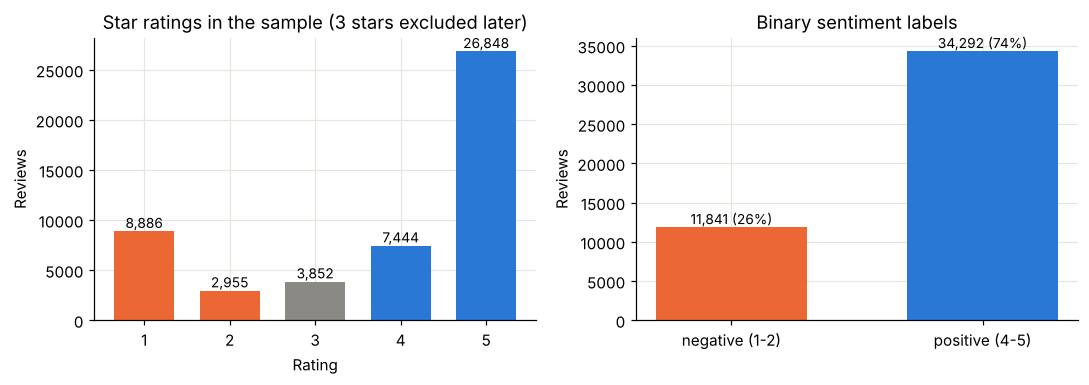

In [4]:
df = sample.loc[~is_empty].copy()
df["Reviews"] = df["Reviews"].str.strip()

rating_counts = df["Rating"].value_counts().sort_index()

df = df[df["Rating"] != 3].copy()
df["label"] = (df["Rating"] >= 4).astype(int)   # 1 = positive and 0 = negative
label_counts = df["label"].map({1: "positive", 0: "negative"}).value_counts()
print(rating_counts.to_string())
print()
print(label_counts.to_string())
print("Negative share: %.1f%%" % (100 * (df["label"] == 0).mean()))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
colors = [NEG_COLOR, NEG_COLOR, GREY, POS_COLOR, POS_COLOR]
axes[0].bar(rating_counts.index.astype(str), rating_counts.values, color=colors, width=0.7)
axes[0].set_title("Star ratings in the sample (3 stars excluded later)")
axes[0].set_xlabel("Rating")
axes[0].set_ylabel("Reviews")
for x, v in zip(rating_counts.index.astype(str), rating_counts.values):
    axes[0].text(x, v, f"{v:,}", ha="center", va="bottom", fontsize=9)

axes[1].bar(["negative (1-2)", "positive (4-5)"],
            [label_counts["negative"], label_counts["positive"]],
            color=[NEG_COLOR, POS_COLOR], width=0.6)
axes[1].set_title("Binary sentiment labels")
axes[1].set_ylabel("Reviews")
for i, v in enumerate([label_counts["negative"], label_counts["positive"]]):
    axes[1].text(i, v, f"{v:,} ({v / label_counts.sum():.0%})", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR / "01_rating_distribution.png", bbox_inches="tight")
plt.show()

**Plot 1. Rating and sentiment distribution.** The left chart shows that five star reviews dominate. One star is the second largest group. Ratings are polarised and few people give two or three stars. After dropping 3 star reviews about 26% of the rows are negative.

**How it affects decisions**

* The classes are imbalanced. A model that always says positive would already get about 74% accuracy. Accuracy alone is therefore misleading. We use **macro F1** as the main metric because it weights both classes equally.
* The negative class is the one a seller cares about. We also report **negative class precision and recall**.
* We set `class_weight="balanced"` in the classifier so that negative errors are not cheap during training.

### 2.3 Exact duplicates and conflicting labels

In [5]:
def normalise(text: str) -> str:
    """Lowercase, drop punctuation and collapse whitespace.

    This makes "Great!" and "great" or "___I have owned" and "I have owned" count as
    the same text. Two reviews with the same key are treated as duplicates.
    """
    text = re.sub(r"[\W_]+", " ", text.lower())
    return re.sub(r"\s+", " ", text).strip()

df["text_key"] = df["Reviews"].map(normalise)
no_words = df["text_key"].eq("")
print("Reviews with no letters or digits (only emoji or punctuation):", int(no_words.sum()))
print(df.loc[no_words, "Reviews"].value_counts().head(8).to_string())
df = df.loc[~no_words].copy()
print()
dup_stats = df.groupby("text_key").agg(
    copies=("label", "size"),
    n_labels=("label", "nunique"),
    pos_share=("label", "mean"),
    n_products=("Product Name", "nunique"),
)
dups = dup_stats[dup_stats["copies"] > 1]
conflicts = dup_stats[dup_stats["n_labels"] > 1]

print("Rows before de-duplication:", len(df))
print("Unique review texts:", len(dup_stats))
print("Texts that appear more than once:", len(dups), "covering", int(dups["copies"].sum()), "rows")
print("Repeated texts that span more than one product name:", int((dups["n_products"] > 1).sum()))
print("Texts with conflicting labels:", len(conflicts), "covering", int(conflicts["copies"].sum()), "rows")
print()
print("Most repeated texts")
display(dups.sort_values("copies", ascending=False).head(10))
print("Conflicting texts")
display(conflicts.sort_values("copies", ascending=False).head(12))

Reviews with no letters or digits (only emoji or punctuation): 55
Reviews
👍         17
:)         6
😀          3
👍👍👍👍👍👍     3
:-)        2
👍👍👍        2
😊          2
💯👍🏽        2

Rows before de-duplication: 46078
Unique review texts: 32738
Texts that appear more than once: 5238 covering 18578 rows
Repeated texts that span more than one product name: 4698
Texts with conflicting labels: 27 covering 2364 rows

Most repeated texts


,copies,n_labels,pos_share,n_products
text_key,,,,
good,735,2,0.991837,466
excelente,660,1,1.000000,346
excellent,636,2,0.998428,437
very good,381,1,1.000000,296
excelent,283,1,1.000000,203
great,281,2,0.989324,229
great phone,242,1,1.000000,203
love it,225,1,1.000000,196
perfect,199,1,1.000000,169


Conflicting texts


,copies,n_labels,pos_share,n_products
text_key,,,,
good,735,2,0.991837,466
excellent,636,2,0.998428,437
great,281,2,0.989324,229
ok,148,2,0.939189,130
great product,101,2,0.990099,95
thanks,73,2,0.945205,67
muy bueno,71,2,0.943662,57
nice phone,64,2,0.984375,62
bueno,55,2,0.981818,50


**What we found.** Duplicates are a big issue in this dataset. About 18,600 rows share their text with at least one other row. Most of them are very short reviews such as "good" or "excelente" or "great phone". Many of them also appear under several product names. This happens because Amazon shows the same review on every colour or storage variant of a listing.

If we split without handling this the same text would sit in both development and test data. The test score would then reward memorising text rather than generalising.

Only 27 repeated texts have conflicting labels. Most conflicts are tiny. For example "good" is positive in 99% of its 735 copies. The rare negative copy is most likely a mismatch between text and stars.

In [6]:
AGREEMENT_THRESHOLD = 0.80

def collapse_duplicates(frame: pd.DataFrame, threshold: float = AGREEMENT_THRESHOLD) -> pd.DataFrame:
    """Keep one row per normalised text.

    The label is the majority label. Texts whose majority share is below the
    threshold are dropped because their label is close to a coin flip. The kept
    row comes from the most common product name for that text.
    """
    rows = []
    for key, grp in frame.groupby("text_key", sort=False):
        share_pos = grp["label"].mean()
        agreement = max(share_pos, 1 - share_pos)
        if agreement < threshold:
            continue
        majority = int(share_pos >= 0.5)
        top_product = grp["Product Name"].value_counts().index[0]
        keep = grp[(grp["label"] == majority) & (grp["Product Name"] == top_product)]
        if keep.empty:
            keep = grp[grp["label"] == majority]
        row = keep.iloc[0].copy()
        row["copies"] = len(grp)
        rows.append(row)
    return pd.DataFrame(rows).reset_index(drop=True)

clean = collapse_duplicates(df)
dropped_conflicts = conflicts[conflicts["pos_share"].between(1 - AGREEMENT_THRESHOLD, AGREEMENT_THRESHOLD, inclusive="neither")]
print("Conflicting texts dropped (agreement below 80%):", len(dropped_conflicts))
display(dropped_conflicts)
print("Rows after de-duplication:", len(clean))
print("Negative share after de-duplication: %.1f%%" % (100 * (clean["label"] == 0).mean()))
print("Unique product names:", clean["Product Name"].nunique())

Conflicting texts dropped (agreement below 80%): 10


,copies,n_labels,pos_share,n_products
text_key,,,,
battery problems,3,2,0.333333,3
couldn t get it to work,3,2,0.333333,3
i liked it,4,2,0.750000,4
i love,12,2,0.666667,11
name,3,2,0.666667,3
no,8,2,0.375000,8
not bad for the price,3,2,0.666667,3
not good,4,2,0.250000,4
pretty good,4,2,0.750000,4


Rows after de-duplication: 32728
Negative share after de-duplication: 30.0%
Unique product names: 3033


**Duplicate and conflict policy**

1. Texts are compared after lowercasing and removing punctuation and extra spaces. 55 reviews made only of emoji or punctuation have no words left and are dropped. A bag of words model cannot read them anyway.
2. Each repeated text is collapsed to **one row** before any split. Its label is the majority label.
3. If the majority covers less than 80% of the copies the text is **dropped**. Ten texts such as "no" and "i love" and "pretty good" fall in this group. Their label is close to a coin flip and would only add noise.
4. The kept row is assigned to the product name where the text appears most often. This product name is later used for the group split.

After this step we have 32,728 unique reviews from 3,033 product names. The negative share rises from 26% to 30% because most removed copies were short positive reviews.

### 2.4 Review length by sentiment

,count,mean,std,min,25%,50%,75%,95%,max
label,,,,,,,,,
negative,9824.0,52.1,77.3,1.0,14.0,30.0,61.0,167.0,1622.0
positive,22904.0,45.6,99.0,1.0,8.0,20.0,44.0,168.0,5313.0


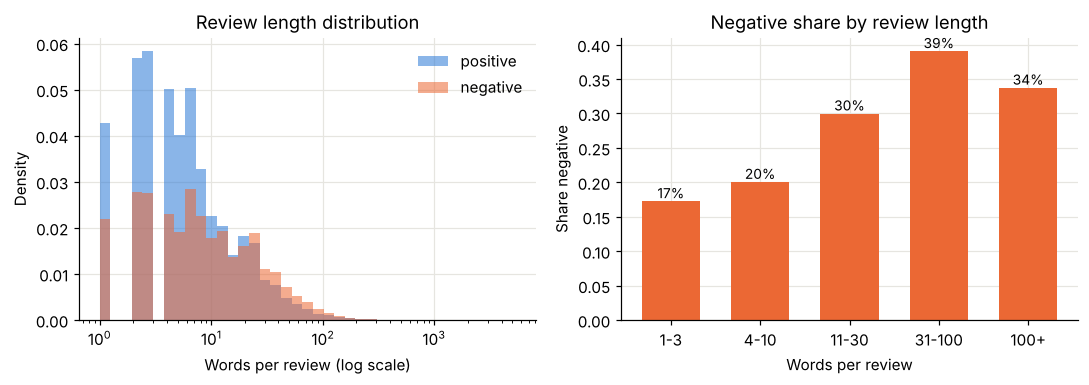

In [7]:
clean["n_words"] = clean["Reviews"].str.split().str.len()
length_summary = clean.groupby(clean["label"].map({0: "negative", 1: "positive"}))["n_words"].describe(
    percentiles=[0.25, 0.5, 0.75, 0.95]
).round(1)
display(length_summary)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
bins = np.logspace(0, np.log10(clean["n_words"].max() + 1), 40)
for lab, color, name in [(1, POS_COLOR, "positive"), (0, NEG_COLOR, "negative")]:
    axes[0].hist(clean.loc[clean["label"] == lab, "n_words"], bins=bins, color=color,
                 alpha=0.55, label=name, density=True)
axes[0].set_xscale("log")
axes[0].set_xlabel("Words per review (log scale)")
axes[0].set_ylabel("Density")
axes[0].set_title("Review length distribution")
axes[0].legend(frameon=False)

length_bins = pd.cut(clean["n_words"], [0, 3, 10, 30, 100, 10_000],
                     labels=["1-3", "4-10", "11-30", "31-100", "100+"])
neg_rate = clean.groupby(length_bins, observed=True)["label"].apply(lambda s: (s == 0).mean())
axes[1].bar(neg_rate.index.astype(str), neg_rate.values, color=NEG_COLOR, width=0.65)
axes[1].set_xlabel("Words per review")
axes[1].set_ylabel("Share negative")
axes[1].set_title("Negative share by review length")
for x, v in zip(neg_rate.index.astype(str), neg_rate.values):
    axes[1].text(x, v, f"{v:.0%}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR / "02_review_length.png", bbox_inches="tight")
plt.show()

**Plot 2. Review length by sentiment.** Negative reviews are longer. The median negative review has 30 words and the median positive review has 20. The right chart shows that only 17% of reviews with one to three words are negative. That rises to 39% for reviews with 31 to 100 words. Unhappy customers explain what went wrong. Happy customers often write two words.

**How it affects decisions**

* Length is a real signal. TF-IDF with `sublinear_tf=True` dampens repeated words so long reviews do not dominate through raw counts.
* Very short reviews give the model little to work with. We check errors by length after testing.
* We keep long reviews. They are the most informative ones for the seller analysis.

### 2.5 Common words and phrases

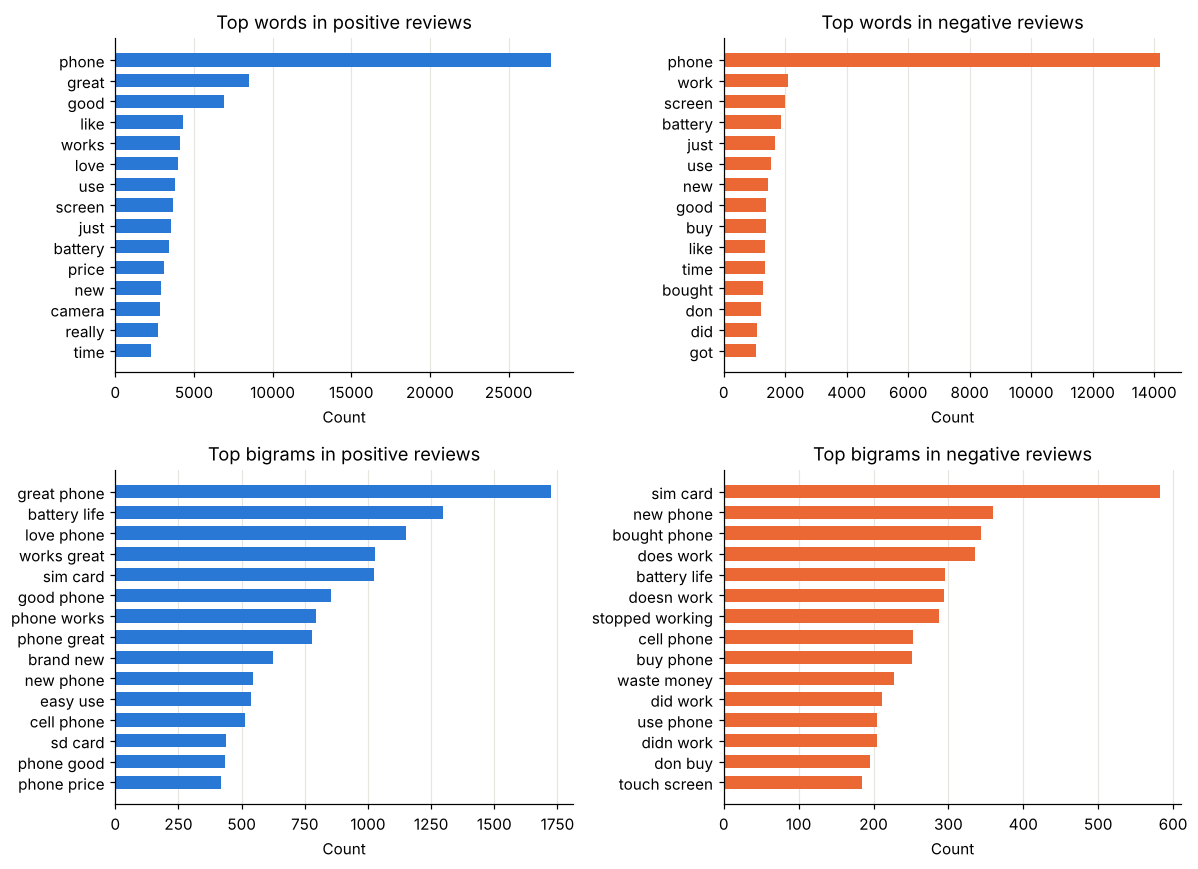

In [8]:
def top_terms(texts, ngram_range, k=15):
    vec = CountVectorizer(ngram_range=ngram_range, stop_words="english", min_df=5)
    counts = vec.fit_transform(texts)
    totals = np.asarray(counts.sum(axis=0)).ravel()
    order = totals.argsort()[::-1][:k]
    return pd.Series(totals[order], index=np.array(vec.get_feature_names_out())[order])

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for col, (lab, color, name) in enumerate([(1, POS_COLOR, "positive"), (0, NEG_COLOR, "negative")]):
    texts = clean.loc[clean["label"] == lab, "Reviews"]
    for row, ngr in enumerate([(1, 1), (2, 2)]):
        terms = top_terms(texts, ngr)
        ax = axes[row, col]
        ax.barh(terms.index[::-1], terms.values[::-1], color=color, height=0.65)
        ax.set_title(f"Top {'words' if ngr == (1, 1) else 'bigrams'} in {name} reviews")
        ax.set_xlabel("Count")
        ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "03_common_terms.png", bbox_inches="tight")
plt.show()

**Plot 3. Common words and phrases.** Positive reviews are dominated by "great" and "love" and "works great" and "battery life". Negative reviews talk about "sim card" and "stopped working" and "waste money" and "touch screen".

The plot also shows an important pitfall. With a standard English stop word list the phrase "doesn't work" becomes "doesn work" and "does work". Words such as "not" and "no" are removed even though they flip the meaning.

**How it affects decisions**

* The model does **not** remove stop words. Negation words are kept so bigrams such as "not working" can be learned.
* Bigrams look useful because many complaints are two word phrases. We test this directly in the model comparison.
* "sim card" and "battery life" appear in both classes. Topic words alone do not reveal sentiment. Context does.

### 2.6 Manual inspection of reviews

Star ratings are a proxy for sentiment. They are not perfect ground truth. Below we read a random set of 24 reviews and then a targeted set of reviews where the text and rating may disagree.

In [9]:
inspect = clean.sample(24, random_state=7)[["Rating", "label", "Reviews"]]
for i, r in enumerate(inspect.itertuples(), 1):
    print(f"[{i:02d}] {r.Rating} stars | {r.Reviews[:260]}")

[01] 5 stars | It was a gift for my mother and she loved it .
[02] 5 stars | Surpasses my expectations.
[03] 1 stars | This phone is great if all you do is search the web and make phone calls. Other than that, it heats up and becomes unusable. I recommend the Nexus 5x over this phone. Games would scream to a halt, so that is why it gets 1 star. If I could at least play Pokemon
[04] 5 stars | Perfect! Couldn't be happier with the quality and the price!
[05] 5 stars | Very nice excellent quality thank you very nice to use to connect to the excellent sound is clear and features a beautiful thank you excellent packaging and fast shipping
[06] 1 stars | honestly this phone worked for like 2 months then it started to mess up and it didnt charge right it kept glitching and freezing. i honestly wasted my money for nothing, so dont buy this phone. the only reason why i still use it is because i paid $400 for it a
[07] 5 stars | Is nice product...
[08] 5 stars | Excellent phone I am very impress

**Reading 24 random reviews.** Most ratings match the text well. Some cases are worth noting.

* **Mixed reviews.** Review 06 gives 5 stars but complains that the phone keeps saying it does not recognise the SIM card. Review 22 gives 4 stars but is "a bit disappointed". The star rating reflects an overall judgement and the text holds both praise and complaints.
* **Negative ratings that are not about phone quality.** Review 17 says wine damaged the handset and review 08 says the phone broke after a drop. The customer is unhappy so the negative label is correct for sentiment. But a seller should not read these as product defects.
* **Seller and delivery experience.** Review 16 (1 star) complains about a foreign version in an opened box. Review 23 (2 stars) mentions an 18 day delivery and missing features. These are real negative experiences even though they are partly about the seller.
* **Non English text.** Reviews 04 and 07 are Spanish ("Espectacular" and "Genial"). The model can only learn these if they appear often enough in training.

Overall about 21 of the 24 random reviews have a rating that clearly fits the text. The remaining three are mixed rather than wrong.

In [10]:
positive_cues = r"\b(?:love|great|excellent|perfect|amazing|awesome)\b"
negative_cues = r"\b(?:broken|doesn'?t work|not working|stopped working|defective|refund|return(?:ed)?|scam|terrible|worst)\b"

neg_text_high_star = clean[(clean["label"] == 1) & clean["Reviews"].str.contains(negative_cues, case=False, regex=True)
                           & ~clean["Reviews"].str.contains(positive_cues, case=False, regex=True)]
pos_text_low_star = clean[(clean["label"] == 0) & clean["Reviews"].str.contains(positive_cues, case=False, regex=True)
                          & ~clean["Reviews"].str.contains(negative_cues, case=False, regex=True)
                          & (clean["n_words"] <= 25)]
print("High star reviews with only negative cue words:", len(neg_text_high_star))
print("Short low star reviews with only positive cue words:", len(pos_text_low_star))
print()
print("== Rated 4-5 but the text reads negative ==")
for r in neg_text_high_star.sample(8, random_state=1).itertuples():
    print(f"{r.Rating} stars | {r.Reviews[:240]}")
print()
print("== Rated 1-2 but the text reads positive ==")
for r in pos_text_low_star.sample(8, random_state=1).itertuples():
    print(f"{r.Rating} stars | {r.Reviews[:240]}")

High star reviews with only negative cue words: 248
Short low star reviews with only positive cue words: 92

== Rated 4-5 but the text reads negative ==
4 stars | I was going to return it because it was unlock from Verizon carrier, an info that should be provided to the customer. I data factory reset right away because who knows what else the seller/unlocked put in your phone. I suggest you do the sa
4 stars | This is a review comparing this phone to the HTC Desire Eye, on Android 6.0 Marshmallow.I got this phone with the Sony MicroSD 64GB deal for $306 ish after tax & free one-day shipping. Amazon told me I'd get it by the 15th, but it literally
4 stars | Charger for phone not working properly -
4 stars | The charger is not working.....
4 stars | This is my first smartphone, but I'm generally familiar with modern electronics as a retired mechanical engineer and PC enthusiast. Even with this capability, I've been initially disappointed because the phone is NOT user-friendly. It took 
5

**Targeted search for inconsistent reviews.** We searched for high star reviews with only negative cue words and short low star reviews with only positive cue words. This gave 248 and 92 candidates. Reading them shows three kinds of cases.

1. **Clear rating errors.** "Charger for phone not working properly" and "The charger is not working" have 4 stars. A customer probably clicked the wrong star or rated the phone while complaining about the charger. These are true label noise.
2. **Keyword false alarms.** "This was great for a few months then nothing but trouble" has 1 star. It contains "great" but the review is clearly negative. "It is not a great phone" is the same. Here the rating is right and a simple keyword rule is wrong. This shows why we need a model that sees word context.
3. **Mixed reviews.** "Everything except the battery life is great" (2 stars) and the 5 star review listing pros and cons. The rating summarises a trade off. Neither label is wrong.

**Conclusion.** Star ratings are a good but noisy proxy. A small share of labels are wrong. That sets a ceiling on measured accuracy. Some "errors" on the test set will be cases where the model reads the text correctly and the star rating disagrees.

## 3. A fair evaluation plan

**What this evaluation measures.** The test set answers one question. *How well does the model predict sentiment for reviews of phones whose product name never appeared in development data?* That is the realistic use case. A seller lists a new phone and wants to monitor its reviews from day one.

**Why a random split is not enough.** Reviews of the same product share vocabulary such as model names and specific defects. With a random split the model could score well by recognising products instead of sentiment. Splitting by product name prevents that.

**The plan**

1. Collapse duplicate texts first (done above) so identical text cannot cross the split.
2. Hold out about 20% of **product names** with `GroupShuffleSplit`. All reviews of a held out product go to the test set.
3. Use the remaining development data for every decision. That includes preprocessing choices and model comparison and tuning.
4. Inside development data use `StratifiedGroupKFold` with 5 folds and product name as the group. Each validation fold again contains only unseen products. Stratification keeps the class balance similar across folds.
5. Touch the test set once at the end with a frozen pipeline.

**Limitation.** Product names are not perfect groups. The same phone in two colours has two product names. Some similar products can therefore sit on both sides. The test score is still far more honest than a random split.

In [11]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
dev_idx, test_idx = next(splitter.split(clean, clean["label"], groups=clean["Product Name"]))
dev = clean.iloc[dev_idx].reset_index(drop=True)
test = clean.iloc[test_idx].reset_index(drop=True)

summary = pd.DataFrame({
    "reviews": [len(dev), len(test)],
    "product_names": [dev["Product Name"].nunique(), test["Product Name"].nunique()],
    "negative_share": [(dev["label"] == 0).mean().round(3), (test["label"] == 0).mean().round(3)],
}, index=["development", "test"])
display(summary)

shared_products = set(dev["Product Name"]) & set(test["Product Name"])
shared_texts = set(dev["text_key"]) & set(test["text_key"])
print("Product names in both sets:", len(shared_products))
print("Identical normalised texts in both sets:", len(shared_texts))
assert not shared_products and not shared_texts

X_dev, y_dev, g_dev = dev["Reviews"], dev["label"], dev["Product Name"]
X_test, y_test = test["Reviews"], test["label"]
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

,reviews,product_names,negative_share
development,26668,2426,0.300
test,6060,607,0.302


Product names in both sets: 0
Identical normalised texts in both sets: 0


The split gives 26,668 development reviews from 2,426 products and 6,060 test reviews from 607 products. Both sets have about 30% negative reviews. The checks confirm that no product name and no normalised text appears in both sets.

## 4. Build and compare models

**Metrics**

* **Macro F1** is the main metric. It averages the F1 score of both classes so the minority negative class counts as much as the positive class.
* **Accuracy** is reported for context. It is easy to read but flattered by imbalance.
* **Negative precision** answers "when the model flags a complaint is it really one".
* **Negative recall** answers "what share of real complaints does the model catch". For a seller this is the most important number because a missed complaint is a missed problem.
* **Training cost** is measured as mean fit time per fold and vocabulary size.

**Models**

* A **most frequent class baseline** that always predicts positive.
* **Logistic regression** on TF-IDF features with **unigrams** only.
* The same logistic regression with **unigrams and bigrams**.

Logistic regression is a strong and fast linear model for sparse text. Its weights are also easy to explain to a seller. Every preprocessing step lives inside a scikit-learn `Pipeline`. The TF-IDF vocabulary is therefore refit on the training part of each fold and never sees the validation fold.

In [12]:
SCORING = {
    "macro_f1": "f1_macro",
    "accuracy": "accuracy",
    "neg_precision": make_scorer(precision_score, pos_label=0, zero_division=0),
    "neg_recall": make_scorer(recall_score, pos_label=0, zero_division=0),
}

def make_lr_pipeline(ngram_range=(1, 1), min_df=2, C=1.0):
    return Pipeline([
        ("tfidf", TfidfVectorizer(lowercase=True, ngram_range=ngram_range, min_df=min_df,
                                  sublinear_tf=True, strip_accents="unicode")),
        ("clf", LogisticRegression(C=C, class_weight="balanced", max_iter=2000, solver="liblinear")),
    ])

def evaluate_cv(name, pipeline):
    res = cross_validate(pipeline, X_dev, y_dev, groups=g_dev, cv=cv, scoring=SCORING, n_jobs=1)
    n_features = None
    if "tfidf" in getattr(pipeline, "named_steps", {}):
        n_features = len(pipeline.fit(X_dev, y_dev).named_steps["tfidf"].vocabulary_)
    row = {"model": name}
    for metric in SCORING:
        vals = res[f"test_{metric}"]
        row[metric] = vals.mean()
        row[f"{metric}_sd"] = vals.std()
    row["fit_seconds"] = res["fit_time"].mean()
    row["predict_seconds"] = res["score_time"].mean()
    row["n_features"] = n_features
    return row

cv_rows = [
    evaluate_cv("Most frequent class", DummyClassifier(strategy="most_frequent")),
    evaluate_cv("LogReg unigrams", make_lr_pipeline((1, 1))),
    evaluate_cv("LogReg unigrams + bigrams", make_lr_pipeline((1, 2))),
]
cv_table = pd.DataFrame(cv_rows).set_index("model")
display(cv_table[["macro_f1", "macro_f1_sd", "accuracy", "neg_precision", "neg_recall",
                  "fit_seconds", "predict_seconds", "n_features"]].round(4))

,macro_f1,macro_f1_sd,accuracy,neg_precision,neg_recall,fit_seconds,predict_seconds,n_features
model,,,,,,,,
Most frequent class,0.4119,0.0001,0.7004,0.0000,0.0000,0.0018,0.0066,NaN
LogReg unigrams,0.9027,0.0050,0.9157,0.8218,0.9176,0.6156,0.1189,11520.0
LogReg unigrams + bigrams,0.9111,0.0070,0.9233,0.8382,0.9222,1.4719,0.2463,100766.0


**Results**

* The baseline gets 70% accuracy but a macro F1 of only 0.41. It never finds a single negative review. This confirms that accuracy alone would be misleading.
* Unigram logistic regression jumps to a macro F1 of 0.903 with negative recall of 0.918.
* Adding bigrams improves macro F1 to 0.911 and negative precision from 0.822 to 0.838. The gain is larger than one fold standard deviation. Both models were scored on the same folds so the comparison is paired and fair. Bigrams capture phrases such as "not working" and "waste money" that single words miss.
* The cost is a vocabulary about nine times larger (about 101,000 features versus 11,500). Training takes about 1.5 seconds per fold instead of 0.6. Both are cheap in absolute terms.

## 5. Tune with GridSearchCV on development data only

We run a small grid with 12 settings. Each one is scored with the same 5 group aware folds.

| Parameter | Values | Why it matters |
|---|---|---|
| `ngram_range` | unigrams only and unigrams plus bigrams | Confirms the bigram result inside the tuned setting |
| `min_df` | 2 and 5 | Drops rare terms. A higher value gives a smaller and more robust vocabulary |
| `C` | 0.5 and 2 and 8 | Inverse regularisation strength. Higher C fits the training data more closely |

The grid is refit on macro F1. Negative precision and recall are tracked as extra scores.

In [13]:
param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [2, 5],
    "clf__C": [0.5, 2.0, 8.0],
}
grid = GridSearchCV(
    make_lr_pipeline(),
    param_grid=param_grid,
    scoring=SCORING,
    refit="macro_f1",
    cv=cv,
    n_jobs=2,
    return_train_score=False,
)
t0 = time.perf_counter()
grid.fit(X_dev, y_dev, groups=g_dev)
print(f"Grid search time: {time.perf_counter() - t0:.0f} s for {len(grid.cv_results_['params'])} settings x 5 folds")

grid_table = pd.DataFrame(grid.cv_results_)
grid_table = grid_table.assign(
    ngram_range=grid_table["param_tfidf__ngram_range"].astype(str),
    min_df=grid_table["param_tfidf__min_df"],
    C=grid_table["param_clf__C"],
)[["ngram_range", "min_df", "C", "mean_test_macro_f1", "std_test_macro_f1", "mean_test_accuracy",
   "mean_test_neg_precision", "mean_test_neg_recall", "mean_fit_time", "rank_test_macro_f1"]]
grid_table = grid_table.sort_values("rank_test_macro_f1").reset_index(drop=True)
display(grid_table.round(4))
print("Best by mean macro F1:", grid.best_params_)

Grid search time: 42 s for 12 settings x 5 folds


,ngram_range,min_df,C,mean_test_macro_f1,std_test_macro_f1,mean_test_accuracy,mean_test_neg_precision,mean_test_neg_recall,mean_fit_time,rank_test_macro_f1
0,"(1, 2)",2,8.0,0.9187,0.0056,0.9309,0.8686,0.9066,1.7044,1
1,"(1, 2)",5,8.0,0.9173,0.0069,0.9296,0.8647,0.9073,1.4991,2
2,"(1, 2)",2,2.0,0.9165,0.0060,0.9283,0.8520,0.9208,1.5268,3
3,"(1, 2)",5,2.0,0.9159,0.0057,0.9278,0.8512,0.9199,1.3337,4
4,"(1, 1)",2,2.0,0.9053,0.0035,0.9182,0.8296,0.9151,0.6152,5
5,"(1, 2)",5,0.5,0.9048,0.0065,0.9175,0.8239,0.9218,1.3299,6
6,"(1, 1)",5,2.0,0.9043,0.0036,0.9174,0.8273,0.9153,0.5757,7
7,"(1, 2)",2,0.5,0.9039,0.0064,0.9166,0.8218,0.9219,1.5044,8
8,"(1, 1)",5,8.0,0.9019,0.0045,0.9157,0.8320,0.9008,0.6913,9
9,"(1, 1)",2,8.0,0.9017,0.0039,0.9157,0.8331,0.8986,0.6306,10


Best by mean macro F1: {'clf__C': 8.0, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)}


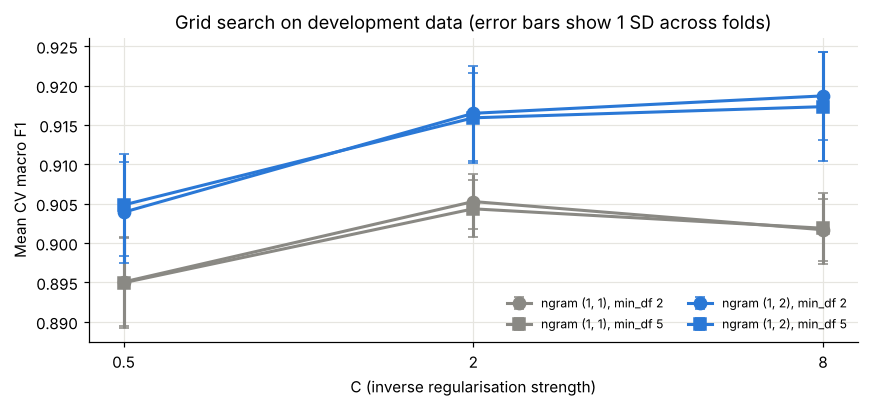

In [14]:
fig, ax = plt.subplots(figsize=(8, 3.8))
markers = {2: "o", 5: "s"}
for ngr, color in [("(1, 1)", GREY), ("(1, 2)", POS_COLOR)]:
    for mdf in [2, 5]:
        sub = grid_table[(grid_table["ngram_range"] == ngr) & (grid_table["min_df"] == mdf)].sort_values("C")
        ax.errorbar(sub["C"], sub["mean_test_macro_f1"], yerr=sub["std_test_macro_f1"], color=color,
                    marker=markers[mdf], markersize=8, linewidth=2, capsize=3,
                    label=f"ngram {ngr}, min_df {mdf}")
ax.set_xscale("log", base=2)
ax.set_xticks([0.5, 2, 8], ["0.5", "2", "8"])
ax.set_xlabel("C (inverse regularisation strength)")
ax.set_ylabel("Mean CV macro F1")
ax.set_title("Grid search on development data (error bars show 1 SD across folds)")
ax.legend(frameon=False, fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig(FIG_DIR / "04_grid_search.png", bbox_inches="tight")
plt.show()

**Plot 4. Grid search results.** Bigram settings (blue) beat unigram settings (grey) at every C. Moving from C = 0.5 to C = 2 gives a clear gain. Moving from 2 to 8 adds very little and the error bars overlap. The choice of `min_df` makes almost no difference.

**How we choose the final pipeline.** We fix a rule before seeing any test result.

1. Keep every setting within one fold standard deviation of the best mean macro F1.
2. Among those prefer the smallest vocabulary.
3. Then prefer the smaller C which means stronger regularisation.

Four bigram settings pass the first step. The rule picks **unigrams + bigrams with `min_df=5` and `C=2`**.

* **Performance.** Its macro F1 is 0.916 against 0.919 for the top setting. The gap is less than half a standard deviation. Its negative recall is 0.920 against 0.907 so it catches more complaints. That matters most for a seller.
* **Simplicity.** Its vocabulary has about 37,000 terms instead of 101,000. Stronger regularisation also makes it less likely to overfit rare phrases.
* **Practical constraints.** The saved model is about 1 MB. It trains in about 2 seconds and scores thousands of reviews per second on a laptop CPU. That is easy to deploy and easy to retrain.

The chosen pipeline is refit on all development data and saved to disk before we look at the test set.

In [15]:
# Selection rule fixed before looking at the test set:
# 1. keep every setting whose mean macro F1 is within one fold SD of the best setting
# 2. among those prefer the smallest vocabulary (cheaper to store and serve)
# 3. then prefer the smaller C (stronger regularisation)
vocab_size = {}
for ngr in param_grid["tfidf__ngram_range"]:
    for mdf in param_grid["tfidf__min_df"]:
        vec = TfidfVectorizer(ngram_range=ngr, min_df=mdf, sublinear_tf=True, strip_accents="unicode")
        vocab_size[(str(ngr), mdf)] = len(vec.fit(X_dev).vocabulary_)
grid_table["n_features"] = [vocab_size[(n, m)] for n, m in zip(grid_table["ngram_range"], grid_table["min_df"])]

best = grid_table.iloc[0]
threshold = best["mean_test_macro_f1"] - best["std_test_macro_f1"]
shortlist = grid_table[grid_table["mean_test_macro_f1"] >= threshold].sort_values(["n_features", "C"])
display(shortlist[["ngram_range", "min_df", "C", "mean_test_macro_f1", "mean_test_neg_recall",
                   "mean_test_neg_precision", "mean_fit_time", "n_features"]].round(4))
chosen = shortlist.iloc[0]
FINAL_PARAMS = {"ngram_range": tuple(int(v) for v in re.findall(r"\d+", chosen["ngram_range"])), "min_df": int(chosen["min_df"]), "C": float(chosen["C"])}

final_pipeline = make_lr_pipeline(**FINAL_PARAMS)
t0 = time.perf_counter()
final_pipeline.fit(X_dev, y_dev)
final_fit_seconds = time.perf_counter() - t0
print("Frozen pipeline:", FINAL_PARAMS)
print(f"Refit on all development data in {final_fit_seconds:.1f} s with "
      f"{len(final_pipeline.named_steps['tfidf'].vocabulary_):,} features")

joblib.dump(final_pipeline, MODEL_DIR / "sentiment_pipeline.joblib")
print("Saved to", MODEL_DIR / "sentiment_pipeline.joblib",
      f"({(MODEL_DIR / 'sentiment_pipeline.joblib').stat().st_size / 1e6:.1f} MB)")

,ngram_range,min_df,C,mean_test_macro_f1,mean_test_neg_recall,mean_test_neg_precision,mean_fit_time,n_features
3,"(1, 2)",5,2.0,0.9159,0.9199,0.8512,1.3337,36932
1,"(1, 2)",5,8.0,0.9173,0.9073,0.8647,1.4991,36932
2,"(1, 2)",2,2.0,0.9165,0.9208,0.8520,1.5268,100766
0,"(1, 2)",2,8.0,0.9187,0.9066,0.8686,1.7044,100766


Frozen pipeline: {'ngram_range': (1, 2), 'min_df': 5, 'C': 2.0}
Refit on all development data in 1.8 s with 36,932 features
Saved to models/sentiment_pipeline.joblib (1.2 MB)


## 6. Final test evaluation of the frozen pipeline

The pipeline above was saved before this section runs. Nothing below changes the model or its settings.

In [16]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_dev, y_dev)

def test_row(name, model):
    t0 = time.perf_counter()
    pred = model.predict(X_test)
    secs = time.perf_counter() - t0
    return {
        "model": name,
        "macro_f1": f1_score(y_test, pred, average="macro"),
        "accuracy": accuracy_score(y_test, pred),
        "neg_precision": precision_score(y_test, pred, pos_label=0, zero_division=0),
        "neg_recall": recall_score(y_test, pred, pos_label=0, zero_division=0),
        "predict_seconds": secs,
    }

test_table = pd.DataFrame([
    test_row("Most frequent class", baseline),
    test_row("Final LogReg pipeline", final_pipeline),
]).set_index("model")

comparison = cv_table[["macro_f1", "accuracy", "neg_precision", "neg_recall", "fit_seconds"]].copy()
comparison.columns = ["dev_cv_" + c for c in comparison.columns]
best_row = grid_table.iloc[0]
comparison.loc["Tuned LogReg (grid best)"] = [best_row["mean_test_macro_f1"], best_row["mean_test_accuracy"],
                                              best_row["mean_test_neg_precision"], best_row["mean_test_neg_recall"],
                                              best_row["mean_fit_time"]]
print("Development cross-validation (5 group-aware folds)")
display(comparison.round(4))
print("Held-out test set (unseen product names)")
display(test_table.round(4))

Development cross-validation (5 group-aware folds)


,dev_cv_macro_f1,dev_cv_accuracy,dev_cv_neg_precision,dev_cv_neg_recall,dev_cv_fit_seconds
model,,,,,
Most frequent class,0.4119,0.7004,0.0000,0.0000,0.0018
LogReg unigrams,0.9027,0.9157,0.8218,0.9176,0.6156
LogReg unigrams + bigrams,0.9111,0.9233,0.8382,0.9222,1.4719
Tuned LogReg (grid best),0.9187,0.9309,0.8686,0.9066,1.7044


Held-out test set (unseen product names)


,macro_f1,accuracy,neg_precision,neg_recall,predict_seconds
model,,,,,
Most frequent class,0.4109,0.6975,0.000,0.0000,0.0001
Final LogReg pipeline,0.9179,0.9290,0.852,0.9264,0.2860


                      precision    recall  f1-score   support

negative (1-2 stars)      0.852     0.926     0.888      1833
positive (4-5 stars)      0.967     0.930     0.948      4227

            accuracy                          0.929      6060
           macro avg      0.909     0.928     0.918      6060
        weighted avg      0.932     0.929     0.930      6060



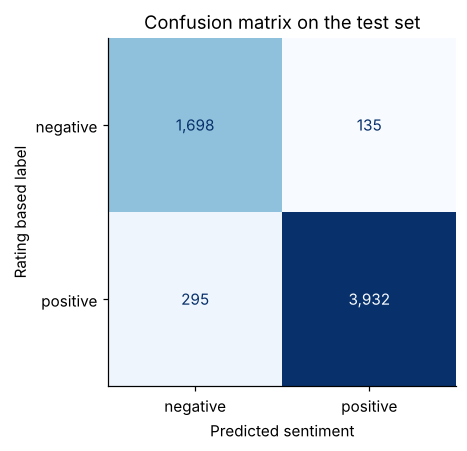

In [17]:
test_pred = final_pipeline.predict(X_test)
test_proba = final_pipeline.predict_proba(X_test)[:, 1]
print(classification_report(y_test, test_pred, target_names=["negative (1-2 stars)", "positive (4-5 stars)"], digits=3))

fig, ax = plt.subplots(figsize=(4.8, 4.2))
cm = confusion_matrix(y_test, test_pred, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["negative", "positive"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format=",")
ax.set_xlabel("Predicted sentiment")
ax.set_ylabel("Rating based label")
ax.set_title("Confusion matrix on the test set")
ax.grid(False)
plt.tight_layout()
plt.savefig(FIG_DIR / "05_confusion_matrix.png", bbox_inches="tight")
plt.show()

**Test results for the frozen pipeline**

| Metric | Development CV (chosen setting) | Test set |
|---|---|---|
| Macro F1 | 0.916 | **0.918** |
| Accuracy | 0.928 | 0.929 |
| Negative precision | 0.851 | 0.852 |
| Negative recall | 0.920 | 0.926 |

The test score closely matches cross validation. This suggests that group aware validation gave an honest estimate and that we did not overfit the development data.

**Plot 5. Confusion matrix.** Of 1,833 negative test reviews the model catches 1,698 and misses 135. Of 4,227 positive reviews it wrongly flags 295 as negative. Because of the balanced class weight the model leans towards flagging complaints. It raises about two false alarms for every missed complaint. For monitoring that is the right trade off. A false alarm costs a seller a few seconds of reading. A missed complaint can hide a defect.

### 6.1 The mistakes that matter most

In [18]:
errors = test.assign(pred=test_pred, p_pos=test_proba)
missed_neg = errors[(errors["label"] == 0) & (errors["pred"] == 1)].sort_values("p_pos", ascending=False)
false_alarm = errors[(errors["label"] == 1) & (errors["pred"] == 0)].sort_values("p_pos")
print(f"Missed negatives (false positives for the positive class): {len(missed_neg)}")
for r in missed_neg.head(10).itertuples():
    print(f"  {r.Rating} stars | P(pos)={r.p_pos:.2f} | {r.Reviews[:200]}")
print()
print(f"False alarms (positive reviews predicted negative): {len(false_alarm)}")
for r in false_alarm.head(10).itertuples():
    print(f"  {r.Rating} stars | P(pos)={r.p_pos:.2f} | {r.Reviews[:200]}")

Missed negatives (false positives for the positive class): 135
  2 stars | P(pos)=1.00 | Acciptable good
  1 stars | P(pos)=0.97 | The best i phone i by it thanx man ♡♡
  1 stars | P(pos)=0.94 | I am happy with what I buy
  2 stars | P(pos)=0.92 | ITs ok for the price
  2 stars | P(pos)=0.91 | smaller than expected.
  2 stars | P(pos)=0.89 | I got this phone because I broke my other phone and needed an inexpensive replacement. This is the first windows phone I've ever had and I miss Android. Shipping took forever and tracking was useless 
  1 stars | P(pos)=0.89 | Reminds me of the old flip phones. It works in the most basic of ways. The key board is terrible. The only 'smart predicting' keyboard is in Japanese. So, if you know it, you may love it.
  1 stars | P(pos)=0.89 | Problems unsolved by the seller, I know that usually the phone is great
  2 stars | P(pos)=0.89 | One of the most user unfriendly phones I have ever used. Too bad. The price was good. Charged super fast.
  2 stars |

In [19]:
errors["length_bucket"] = pd.cut(errors["n_words"], [0, 3, 10, 30, 100, 10_000],
                                 labels=["1-3", "4-10", "11-30", "31-100", "100+"])
by_len = errors.groupby("length_bucket", observed=True).apply(
    lambda g: pd.Series({
        "reviews": len(g),
        "error_rate": (g["label"] != g["pred"]).mean(),
        "neg_recall": recall_score(g["label"], g["pred"], pos_label=0, zero_division=0),
    }), include_groups=False)
display(by_len.round(3))

,reviews,error_rate,neg_recall
length_bucket,,,
1-3,357.0,0.076,0.770
4-10,1279.0,0.054,0.909
11-30,1975.0,0.066,0.930
31-100,1752.0,0.080,0.948
100+,697.0,0.090,0.910


**Which mistakes matter most**

1. **Missed negatives (135 reviews).** These are the costly errors. Several groups stand out.
   * *Mild or polite complaints.* "ITs ok for the price" and "smaller than expected" and "Acciptable good" got 1 or 2 stars. The words are neutral or positive so the model reads them as positive.
   * *Praise followed by a deal breaker.* "Product was in great condition however the battery life is non existent" and "One of the most user unfriendly phones ... The price was good. Charged super fast." The positive words outweigh the single complaint in a bag of words model.
   * *Text and rating mismatch.* "The best i phone i by it thanx man" and "I am happy with what I buy" have 1 star. The text is positive so the model is arguably right and the label is noisy.
2. **False alarms (295 reviews).** Many are 4 or 5 star reviews whose text is plainly negative. Examples are "Didnt work from the day we got it!! Not impressed!" and "Did not include note pen! Very disappointed." Here the model reads the text better than the star rating does. Others describe a problem that was later solved by the seller.
3. **Very short reviews.** Negative recall drops to 0.77 for reviews of one to three words. There is little context and words such as "ok" or "no" are ambiguous.

**What this means.** A large share of the remaining errors come from label noise or genuinely mixed reviews rather than from obvious model failures. Better gains would need aspect level labels or a model that reads word order such as a fine tuned transformer.

## 7. What customers complain about

A seller does not only want a sentiment score. They want to know *why* customers are unhappy. We combine two views.

1. **Model weights.** The logistic regression weights show which words and phrases push a review towards negative or positive.
2. **Concern topics.** A transparent keyword dictionary groups negative reviews into common topics. We compare how often each topic appears in negative versus positive reviews. Each topic is labelled as a *product* issue or a *customer experience* issue (seller or shipping or returns).

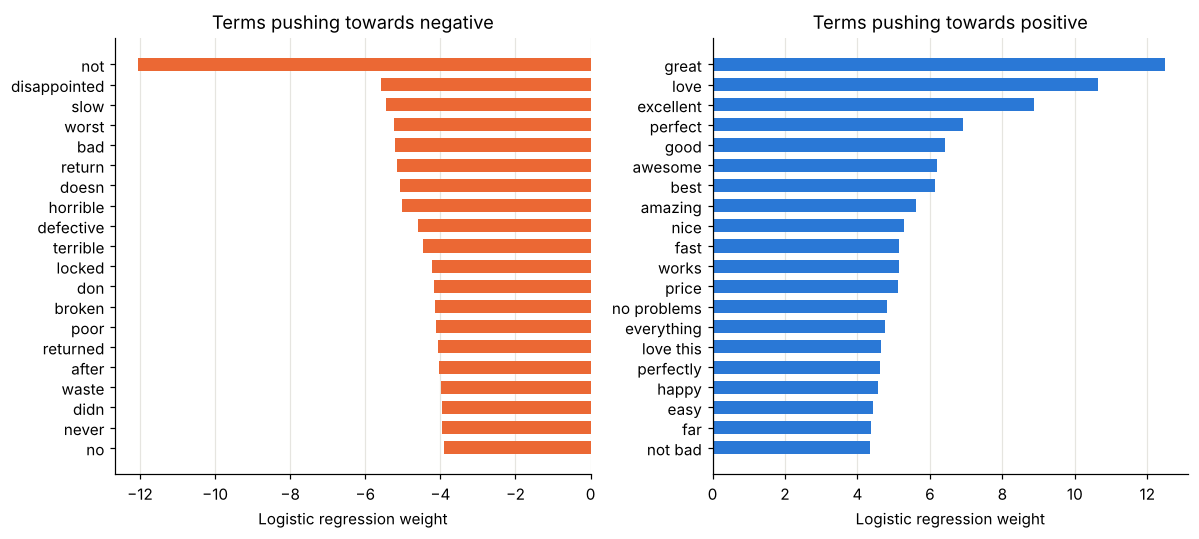

In [20]:
vocab = np.array(final_pipeline.named_steps["tfidf"].get_feature_names_out())
coefs = final_pipeline.named_steps["clf"].coef_[0]
order = np.argsort(coefs)
top_neg = pd.Series(coefs[order[:20]], index=vocab[order[:20]])
top_pos = pd.Series(coefs[order[-20:]], index=vocab[order[-20:]])

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].barh(top_neg.index[::-1], top_neg.values[::-1], color=NEG_COLOR, height=0.65)
axes[0].set_title("Terms pushing towards negative")
axes[0].set_xlabel("Logistic regression weight")
axes[1].barh(top_pos.index, top_pos.values, color=POS_COLOR, height=0.65)
axes[1].set_title("Terms pushing towards positive")
axes[1].set_xlabel("Logistic regression weight")
for ax in axes:
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "06_model_terms.png", bbox_inches="tight")
plt.show()

,negative,positive,lift,type
Network SIM and unlock,0.224,0.154,1.452,product
Returns refunds and support,0.216,0.035,6.152,customer experience
Battery and charging,0.209,0.138,1.512,product
Freezing software and speed,0.174,0.108,1.613,product
Screen and display,0.157,0.120,1.307,product
Seller shipping and delivery,0.144,0.145,0.998,customer experience
Calls audio and speaker,0.127,0.070,1.825,product
Used or refurbished condition,0.122,0.112,1.092,customer experience
Camera,0.081,0.114,0.711,product
Fake or wrong item,0.033,0.012,2.782,customer experience


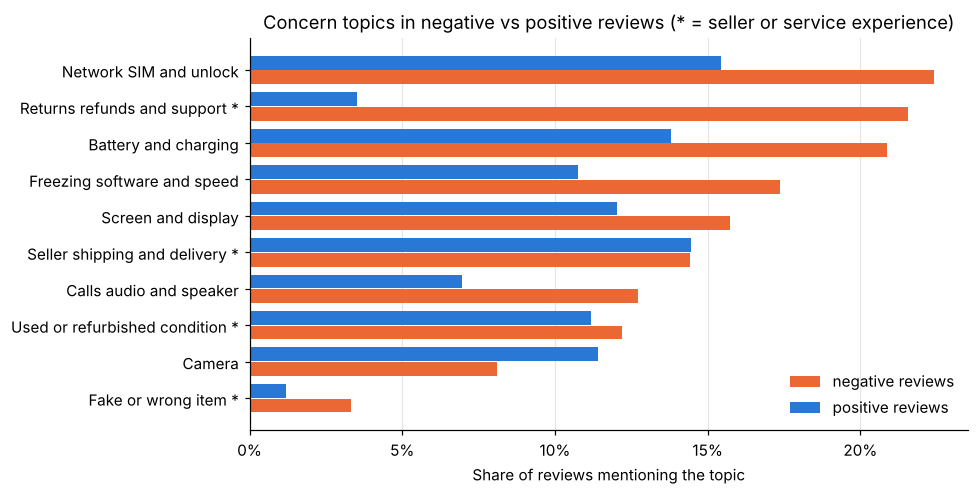

In [21]:
CONCERNS = {
    "Battery and charging": r"\bbatter(y|ies)\b|\bcharg(e|er|ing)\b|\bdrain",
    "Screen and display": r"\bscreen\b|\bdisplay\b|\btouch ?screen\b|\bcrack",
    "Network SIM and unlock": r"\bsim\b|\bunlock|\bnetwork\b|\bcarrier\b|\bsignal\b|\b4g\b|\blte\b|\bverizon\b|\bat&t\b|\bt-?mobile\b",
    "Used or refurbished condition": r"\bused\b|\brefurb|\bscratch|\bcondition\b|\bnot new\b",
    "Seller shipping and delivery": r"\bseller\b|\bship(ping|ped)?\b|\bdeliver|\barriv|\bpackag|\bbox\b",
    "Returns refunds and support": r"\breturn|\brefund|\bwarranty\b|\bcustomer service\b|\bsupport\b",
    "Freezing software and speed": r"\bfreez|\bslow\b|\blag|\bsoftware\b|\bupdate|\brestart|\breboot|\bapps?\b",
    "Calls audio and speaker": r"\bcalls?\b|\bspeaker\b|\bmicrophone\b|\bsound\b|\bvolume\b|\bhear\b",
    "Camera": r"\bcamera\b|\bphotos?\b|\bpictures?\b",
    "Fake or wrong item": r"\bfake\b|\bcounterfeit\b|\bwrong\b|\bnot as described\b|\bnot original\b",
}
EXPERIENCE_CONCERNS = {"Seller shipping and delivery", "Returns refunds and support", "Fake or wrong item",
                       "Used or refurbished condition"}

def concern_rates(frame):
    out = {}
    for name, pat in CONCERNS.items():
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", UserWarning)   # groups in the patterns are only for readability
            out[name] = frame["Reviews"].str.contains(pat, case=False, regex=True).mean()
    return pd.Series(out)

rates = pd.DataFrame({
    "negative": concern_rates(clean[clean["label"] == 0]),
    "positive": concern_rates(clean[clean["label"] == 1]),
})
rates["lift"] = rates["negative"] / rates["positive"]
rates["type"] = ["customer experience" if c in EXPERIENCE_CONCERNS else "product" for c in rates.index]
rates = rates.sort_values("negative")
display(rates.sort_values("negative", ascending=False).round(3))

fig, ax = plt.subplots(figsize=(9, 4.6))
y = np.arange(len(rates))
ax.barh(y - 0.2, rates["negative"], height=0.38, color=NEG_COLOR, label="negative reviews")
ax.barh(y + 0.2, rates["positive"], height=0.38, color=POS_COLOR, label="positive reviews")
ax.set_yticks(y, [f"{c} *" if c in EXPERIENCE_CONCERNS else c for c in rates.index])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Share of reviews mentioning the topic")
ax.set_title("Concern topics in negative vs positive reviews (* = seller or service experience)")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "07_concerns.png", bbox_inches="tight")
plt.show()

In [22]:
neg = clean[clean["label"] == 0].copy()
neg["Brand Name"] = neg["Brand Name"].fillna("Unknown")
top_brands = neg["Brand Name"].value_counts().head(6).index
brand_table = pd.DataFrame({b: concern_rates(neg[neg["Brand Name"] == b]) for b in top_brands}).T
brand_table.insert(0, "negative_reviews", neg["Brand Name"].value_counts().loc[top_brands])
display(brand_table.round(2))

voted = neg[neg["Review Votes"].fillna(0) >= 5].sort_values("Review Votes", ascending=False)
voted = voted[~voted["Reviews"].map(normalise).str[:80].duplicated()]   # near copies of one long review
print(f"Negative reviews with 5 or more helpful votes: {len(voted)}")
for _, r in voted.head(5).iterrows():
    print(f"  votes={int(r['Review Votes'])} | {r['Brand Name']} | {r['Reviews'][:220]}")

,negative_reviews,Battery and charging,Screen and display,Network SIM and unlock,Used or refurbished condition,Seller shipping and delivery,Returns refunds and support,Freezing software and speed,Calls audio and speaker,Camera,Fake or wrong item
Unknown,1514,0.20,0.15,0.23,0.13,0.17,0.22,0.15,0.11,0.07,0.04
Samsung,1446,0.21,0.13,0.27,0.13,0.17,0.24,0.18,0.12,0.07,0.04
BLU,1444,0.21,0.21,0.17,0.06,0.08,0.22,0.26,0.16,0.11,0.02
Apple,1225,0.20,0.13,0.24,0.17,0.18,0.19,0.06,0.10,0.03,0.05
LG,590,0.23,0.20,0.24,0.13,0.16,0.21,0.19,0.12,0.08,0.02
HTC,505,0.25,0.16,0.27,0.13,0.17,0.23,0.19,0.15,0.10,0.04


Negative reviews with 5 or more helpful votes: 882
  votes=478 | Apple | ___I have owned every iPhone since the 3G model. Every year for 7 years I have upgraded. In my household is a slew of Apple products from iPad’s, MacBook’s to iPhones. My household now has 3 new iPhone 7 models. But I am
  votes=296 | Samsung | Buyers Be AwareThis shipper has send me 'FAKE" Samsung cell phone.Everything looks almost similar to the original Samsung but many features do not work especially the Camera makes terrible low pixel pictures, no screen s
  votes=285 | Apple | STAR!!? I PAID $800 AND GOT A FAKE PHONE! THAT'S RIGHT! I GOT A MAQUETTE!THIS WAS A GIFT... AND IT WAS A FAKE PHONE!!? WHAT A SHAME!
  votes=212 | Samsung | I received a fake phone. It doesn't even have a spot for the Sim Card, neither does it charges or turns on. Some S7 details are literally drawn on the plastic. It's just a piece of plastic on a Galaxy S7 shape.
  votes=192 | Apple | The "Unlocked" phone it is unlocked, but unlocked

**Plot 6. Model weights.** The strongest negative signal by far is "not". Other negative terms describe failure and regret such as "disappointed" and "slow" and "return" and "defective" and "locked" and "waste". Positive terms are general praise such as "great" and "love" and "excellent" and "perfect".

Two positive terms prove the value of bigrams. "no problems" and "not bad" carry strong positive weights even though "no" and "not" alone are negative. A unigram model cannot learn this.

**Plot 7. Concern topics.** The chart compares how often each topic is mentioned in negative and positive reviews.

* **Returns and refunds and support** show up in 22% of negative reviews but only 3.5% of positive ones. That is six times more often. Once a customer needs to return a phone the experience usually turns negative.
* **Network and SIM and unlock problems** are the most frequent topic at 22%. Many "unlocked" phones do not work with the buyer's carrier or only on 3G.
* **Battery and charging** (21%) and **freezing or slow software and restarts** (17%) are the main hardware and software complaints.
* **Fake or wrong items** are rare (3%) but appear three times as often in negative reviews. They also attract the most helpful votes. The top voted negative reviews describe fake iPhones and Galaxy phones.
* **Shipping and delivery** words appear equally often in both classes. Delivery is mentioned a lot but is not by itself a driver of negative sentiment.

**By brand.** BLU has the most software and screen complaints (26% and 21% of its negative reviews). Apple and Samsung have more complaints about refurbished condition and fakes and network locks. These are typical of resold flagship phones.

**Actions for a seller**

1. Check carrier and band compatibility before listing and state it clearly.
2. Test the battery and charger on refurbished stock.
3. Make returns easy and fast because that topic has the strongest link to negative reviews.
4. Verify authenticity of high value phones.

### 7.1 Product sentiment versus overall customer experience

**Label noise** means the star rating does not reflect what the customer wrote. "The charger is not working" with 4 stars is label noise. The text and the label disagree.

**A negative customer experience** is different. The customer is truly unhappy but the cause is not the phone itself. Examples are a late delivery or a box that arrived opened or a seller who never replied. "It arrived three weeks late in a damaged box" with 1 star is **not** label noise. The text and rating agree. The customer had a bad experience.

The model predicts **overall customer sentiment**. That is what the star rating measures. A seller or delivery complaint is therefore a correct negative example and we keep it in training. Removing it would teach the model that delivery problems are neutral.

For decisions the seller needs a second layer. The concern topics above separate **product sentiment** (battery and screen and software) from **experience sentiment** (shipping and returns and authenticity). This tells the seller whether to fix the phone or fix the process. For example a 1 star review about a wine damaged handset is negative sentiment but says nothing about product quality. That is why topic analysis sits next to the classifier rather than replacing it.

## 8. Demonstration of the saved model

In [23]:
import sys
sys.path.insert(0, "src")
from predict import load_model, predict_sentiment

model = load_model(MODEL_DIR / "sentiment_pipeline.joblib")
examples = [
    "Great phone. Battery lasts all day and the screen is sharp.",
    "Stopped working after two weeks and the seller never answered my emails.",
    "The phone itself is fine but it arrived three weeks late in a damaged box.",
    "",
    "   ",
    None,
]
for text in examples:
    print(repr(text), "->", predict_sentiment(text, model=model))

'Great phone. Battery lasts all day and the screen is sharp.' -> {'label': 'positive', 'positive_probability': 0.9158, 'message': 'ok'}
'Stopped working after two weeks and the seller never answered my emails.' -> {'label': 'negative', 'positive_probability': 0.0243, 'message': 'ok'}
'The phone itself is fine but it arrived three weeks late in a damaged box.' -> {'label': 'negative', 'positive_probability': 0.0702, 'message': 'ok'}
'' -> {'label': None, 'positive_probability': None, 'message': 'Please enter some review text.'}
'   ' -> {'label': None, 'positive_probability': None, 'message': 'Please enter some review text.'}
None -> {'label': None, 'positive_probability': None, 'message': 'Please enter some review text.'}


## 9. Conclusions and limitations

**Summary**

| Model | Dev CV macro F1 | Test macro F1 | Test negative recall |
|---|---|---|---|
| Most frequent class | 0.412 | 0.411 | 0.000 |
| LogReg unigrams | 0.903 | not tested | not tested |
| LogReg unigrams + bigrams | 0.911 | not tested | not tested |
| **Final LogReg (1,2) min_df=5 C=2** | **0.916** | **0.918** | **0.926** |

Only the baseline and the frozen final pipeline were scored on the test set. The other models were compared on development data only.

**Key findings**

* Handling duplicates was essential. About 40% of rows were repeated text copied across product variants.
* A TF-IDF logistic regression with unigrams and bigrams reaches a macro F1 of about 0.92 on unseen products. It catches about 93% of negative reviews.
* Development and test scores agree closely so the evaluation plan was fair.
* Returns and carrier compatibility are the clearest sources of unhappy customers. Battery and software follow.

**Limitations**

* Star ratings are a noisy proxy. Some test "errors" are label errors.
* 3 star reviews are excluded. In practice a seller would also want a neutral or mixed class.
* Product names are imperfect groups because colour variants have different names.
* Near duplicates that differ by a few words are not merged.
* A bag of words model cannot follow "great but" constructions. A transformer model would likely do better on mixed reviews at a higher serving cost.
* Concern topics come from a hand written keyword list. They are transparent but will miss some phrasings.

**Reproducibility.** The sample and split and folds all use `random_state=42`. The final pipeline is saved in `models/sentiment_pipeline.joblib`. It can be used with `src/predict.py` as described in the README.